# code_089 · Boosting and additive correction

**Book:** section 18.3. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_089).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1889;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1889


<a id="correction"></a>
## Follow a baseline and two residual learners

A fixed thirty-point one-dimensional toy response combines sin(5x), a positive linear trend and generated noiseSD.12. Begin with its training mean and fit two depth1 squared-error trees to successive residuals with learning rate .5. Plot the actual first two correction functions and cumulative fit; verify the arithmetic against stored residuals. This is a training mechanism illustration, not final predictive assessment. Separately verify a logistic negative-loss-gradient y-sigmoid(score) by finite differences. A classification loss gradient is not generally the ordinary residual y-score.


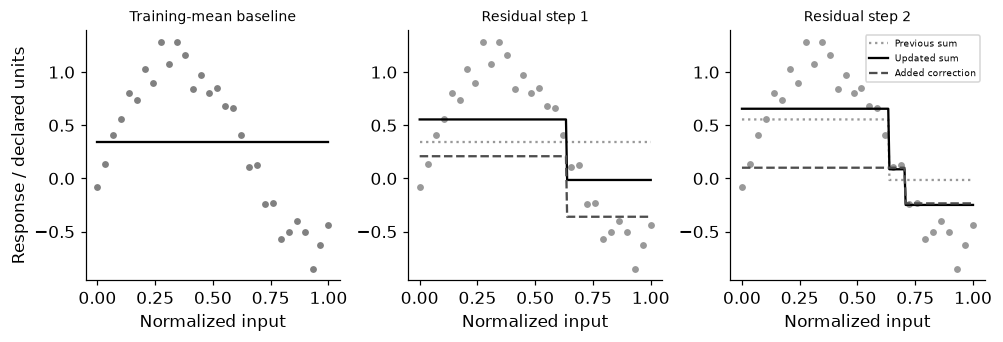

In [2]:
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from scipy.special import expit
x=np.linspace(0,1,30);y=np.sin(5*x)+.5*x+rng.normal(0,.12,len(x));baseline=float(y.mean());prediction=np.full(len(y),baseline);steps=[];losses=[float(mean_squared_error(y,prediction))];grid=np.linspace(0,1,200);curve=np.full(len(grid),baseline);curves=[curve.copy()]
for stage in range(2):
 residual=y-prediction;tree=DecisionTreeRegressor(max_depth=1,random_state=SEED).fit(x[:,None],residual);correction=tree.predict(x[:,None]);updated=prediction+.5*correction;np.testing.assert_allclose(y-updated,residual-.5*correction);steps.append(tree);prediction=updated;curve=curve+.5*tree.predict(grid[:,None]);curves.append(curve.copy());losses.append(float(mean_squared_error(y,prediction)))
assert losses[2]<=losses[1]<=losses[0]
score=.7;label=1.;h=1e-6;loss=lambda f:np.logaddexp(0,f)-label*f;numeric=-(loss(score+h)-loss(score-h))/(2*h);np.testing.assert_allclose(numeric,label-expit(score),atol=1e-9)
RESULTS['two_steps']={'toy_rows':30,'baseline':baseline,'learning_rate':.5,'training_mse_baseline_then_two_steps':losses,'logistic_negative_gradient':float(numeric),'final_prediction_identity_passed':True}
fig,axes=plt.subplots(1,3,figsize=(9,3));axes[0].scatter(x,y,s=12,color='.5');axes[0].plot(grid,curves[0],color='black');axes[0].set(title='Training-mean baseline',ylabel='Response / declared units')
for j in [1,2]:
 axes[j].scatter(x,y,s=12,color='.6');axes[j].plot(grid,curves[j-1],':',color='.6',label='Previous sum');axes[j].plot(grid,curves[j],color='black',label='Updated sum');axes[j].plot(grid,.5*steps[j-1].predict(grid[:,None]),'--',color='.3',label='Added correction');axes[j].set_title(f'Residual step {j}')
for ax in axes:ax.set_xlabel('Normalized input')
axes[2].legend(fontsize=6);plt.show()


<a id="selection"></a>
## Weight hard cases; choose a stage budget before final assessment

A separate binary fixture implements two textbook AdaBoost rounds: weighted stump error e, alpha=.5log((1-e)/e), weights multiplied by exp(-alpha*y*prediction) then normalized. Labels use{-1,+1}. This explicitly declared exponential-loss convention is not an equivalence claim about every library's coefficient normalization. Finally generate independent regression training160/development100/final200 cases. A fixed depth2/minleaf5/learning_rate.1 gradient booster chooses20/80/200 stages using development MSE. Training/development staged losses are diagnostics; final MSE is computed only after stage selection. More rounds are not automatically better, and sequential corrections are different from independently varied bagged fits.


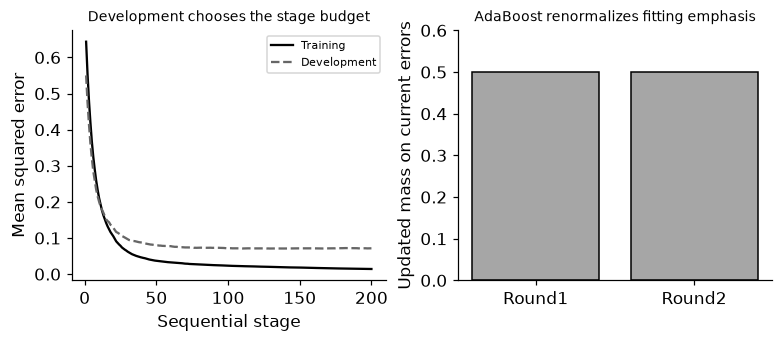

In [3]:
a=rng.uniform(-1,1,(120,2));b=np.where(a[:,0]+.5*a[:,1]+rng.normal(0,.3,120)>0,1,-1);weight=np.full(len(b),1/len(b));rounds=[]
for j in range(2):
 tree=DecisionTreeClassifier(max_depth=1,random_state=SEED+j).fit(a,b,sample_weight=weight);pred=tree.predict(a);error=float(np.sum(weight*(pred!=b)));assert 0<error<.5;alpha=.5*np.log((1-error)/error);before=weight.copy();weight*=np.exp(-alpha*b*pred);weight/=weight.sum();np.testing.assert_allclose(weight.sum(),1);ratio=weight[pred!=b].mean()/weight[pred==b].mean();rounds.append({'weighted_error':error,'alpha':float(alpha),'post_update_weight_mass_on_this_round_errors':float(weight[pred!=b].sum()),'mean_weight_error_to_correct_ratio':float(ratio),'preupdate_weight_sum':float(before.sum())})
def generate(n):
 a=rng.uniform(-1,1,(n,3));return a,np.sin(3*a[:,0])+.7*a[:,1]**2+.4*a[:,2]+rng.normal(0,.2,n)
X,y=generate(160);Xd,yd=generate(100);Xt,yt=generate(200);options=[]
for stages in [20,80,200]:
 model=GradientBoostingRegressor(n_estimators=stages,learning_rate=.1,max_depth=2,min_samples_leaf=5,random_state=SEED).fit(X,y);options.append((float(mean_squared_error(yd,model.predict(Xd))),stages,model))
dev,stages,model=min(options,key=lambda r:r[0]);train_curve=[float(mean_squared_error(y,p)) for p in model.staged_predict(X)];dev_curve=[float(mean_squared_error(yd,p)) for p in model.staged_predict(Xd)];np.testing.assert_allclose(model.predict(Xd),list(model.staged_predict(Xd))[-1]);RESULTS['AdaBoost_rounds']=rounds;RESULTS['selected_gradient_boosting']={'roles':{'training':160,'development':100,'final':200},'stage_grid':[20,80,200],'selected_stages':stages,'learning_rate':.1,'development_mse':dev,'final_mse':float(mean_squared_error(yt,model.predict(Xt))),'candidate_development_mse':[{'stages':v,'mse':s} for s,v,_ in options]}
fig,axes=plt.subplots(1,2,figsize=(7,3));axes[0].plot(np.arange(1,stages+1),train_curve,'-',color='black',label='Training');axes[0].plot(np.arange(1,stages+1),dev_curve,'--',color='.4',label='Development');axes[0].set(xlabel='Sequential stage',ylabel='Mean squared error',title='Development chooses the stage budget');axes[0].legend(fontsize=7);axes[1].bar([0,1],[r['post_update_weight_mass_on_this_round_errors'] for r in rounds],color='.65',edgecolor='black');axes[1].set(xticks=[0,1],xticklabels=['Round1','Round2'],ylim=(0,.6),ylabel='Updated mass on current errors',title='AdaBoost renormalizes fitting emphasis');plt.show()


In [4]:
summary={'example_id':'code_089','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['manual squared-error residual correction', 'loss gradients versus ordinary residuals', 'AdaBoost weight updates', 'development-selected stage count'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["manual squared-error residual correction", "loss gradients versus ordinary residuals", "AdaBoost weight updates", "development-selected stage count"], "elapsed_seconds": 0.545, "example_id": "code_089", "hardware": "Darwin arm64 CPU", "results": {"AdaBoost_rounds": [{"alpha": 0.9729550745276566, "mean_weight_error_to_correct_ratio": 7.0, "post_update_weight_mass_on_this_round_errors": 0.4999999999999999, "preupdate_weight_sum": 0.9999999999999999, "weighted_error": 0.125}, {"alpha": 0.7234594914681627, "mean_weight_error_to_correct_ratio": 2.0, "post_update_weight_mass_on_this_round_errors": 0.5000000000000001, "preupdate_weight_sum": 0.9999999999999998, "weighted_error": 0.1904761904761905}], "selected_gradient_boosting": {"candidate_development_mse": [{"mse": 0.12838929825404416, "stages": 20}, {"mse": 0.0730960072654534, "stages": 80}, {"mse": 0.07139362480418654, "stages": 200}], "development_mse": 0.07139362480418654, "final_mse":